In [3]:
import pandas as pd

In [5]:
import numpy as np

In [7]:
import matplotlib.pyplot as plt 

In [9]:
import seaborn as sns

In [10]:
import os

In [12]:


print(os.getcwd())

c:\Users\mdsih\OneDrive\Documents\Kaggle Project\mkdir climate-risk-data-science\notebooks


In [14]:
import os

print(os.path.abspath("../../data/POWER_Point_Daily_19810101_19811231_023d81N_090d41E_LST.csv"))

c:\Users\mdsih\OneDrive\Documents\Kaggle Project\data\POWER_Point_Daily_19810101_19811231_023d81N_090d41E_LST.csv


In [21]:
df = pd.read_csv(
    "../data/POWER_Point_Daily_19810101_19811231_023d81N_090d41E_LST.csv",
    skiprows=11
)

df.head()

,YEAR,DOY,T2M,RH2M,PRECTOTCORR
0,1981,1,18.63,55.22,0.00
1,1981,2,19.06,51.12,0.00
2,1981,3,19.22,55.75,0.00
3,1981,4,19.11,53.51,0.00
4,1981,5,19.87,58.67,0.03


In [22]:
df["DATE"] = pd.to_datetime(
    df["YEAR"].astype(str) + df["DOY"].astype(str),
    format="%Y%j"
)

df.head()

,YEAR,DOY,T2M,RH2M,PRECTOTCORR,DATE
0,1981,1,18.63,55.22,0.00,1981-01-01
1,1981,2,19.06,51.12,0.00,1981-01-02
2,1981,3,19.22,55.75,0.00,1981-01-03
3,1981,4,19.11,53.51,0.00,1981-01-04
4,1981,5,19.87,58.67,0.03,1981-01-05


In [23]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 365 entries, 0 to 364
Data columns (total 6 columns):
 #   Column       Non-Null Count  Dtype         
---  ------       --------------  -----         
 0   YEAR         365 non-null    int64         
 1   DOY          365 non-null    int64         
 2   T2M          365 non-null    float64       
 3   RH2M         365 non-null    float64       
 4   PRECTOTCORR  365 non-null    float64       
 5   DATE         365 non-null    datetime64[us]
dtypes: datetime64[us](1), float64(3), int64(2)
memory usage: 17.2 KB


In [24]:
df.isnull().sum()

YEAR           0
DOY            0
T2M            0
RH2M           0
PRECTOTCORR    0
DATE           0
dtype: int64

In [25]:
df.duplicated().sum()

np.int64(0)

In [26]:
df[["T2M", "RH2M", "PRECTOTCORR"]].describe()

,T2M,RH2M,PRECTOTCORR
count,365.000000,365.000000,365.000000
mean,25.730137,69.442356,4.204082
std,3.690701,14.728634,8.198337
min,16.310000,33.170000,0.000000
25%,23.540000,57.120000,0.000000
50%,27.280000,69.560000,0.480000
75%,28.570000,83.290000,4.200000
max,30.990000,91.800000,84.610000


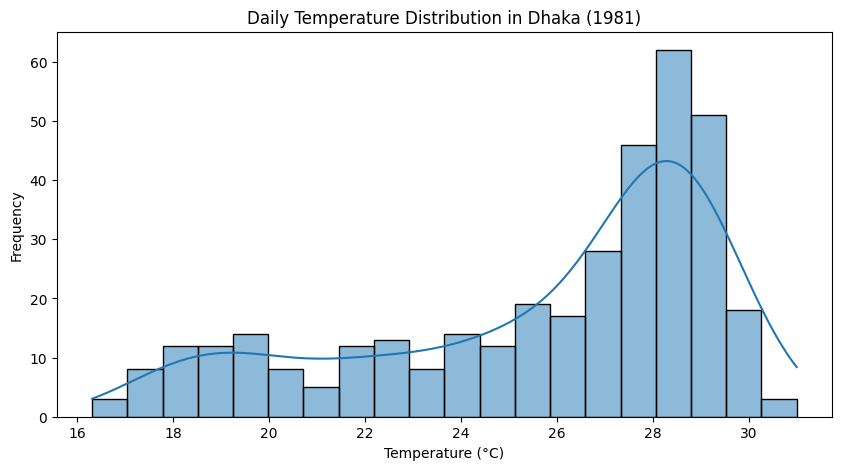

In [27]:
plt.figure(figsize=(10, 5))

sns.histplot(df["T2M"], bins=20, kde=True)

plt.title("Daily Temperature Distribution in Dhaka (1981)")
plt.xlabel("Temperature (°C)")
plt.ylabel("Frequency")

plt.show()

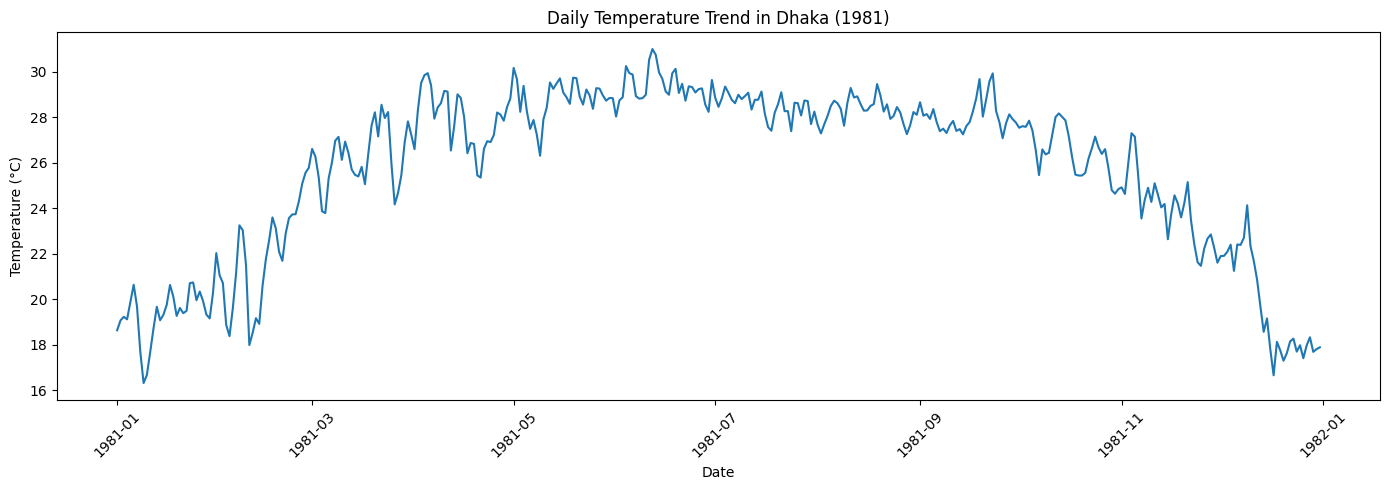

In [28]:
plt.figure(figsize=(14, 5))

plt.plot(df["DATE"], df["T2M"])

plt.title("Daily Temperature Trend in Dhaka (1981)")
plt.xlabel("Date")
plt.ylabel("Temperature (°C)")

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

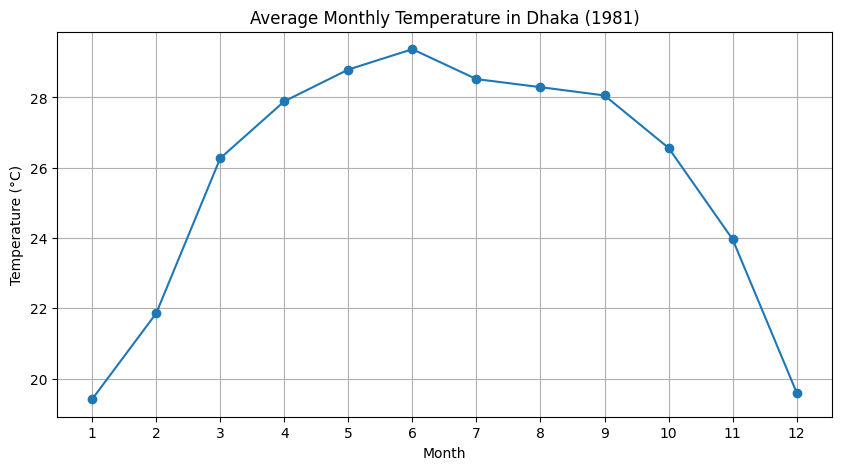

In [29]:
df["MONTH"] = df["DATE"].dt.month

monthly_temp = df.groupby("MONTH")["T2M"].mean()

plt.figure(figsize=(10, 5))
monthly_temp.plot(marker="o")

plt.title("Average Monthly Temperature in Dhaka (1981)")
plt.xlabel("Month")
plt.ylabel("Temperature (°C)")
plt.xticks(range(1, 13))
plt.grid(True)
plt.show()

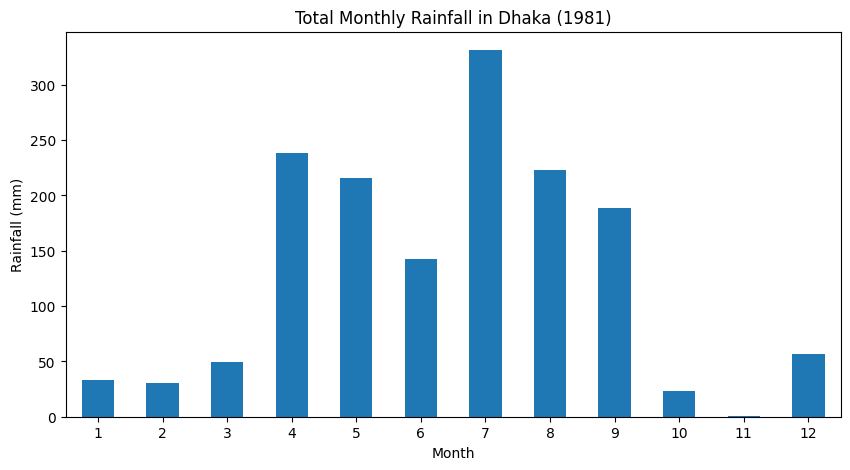

In [30]:
df["MONTH"] = df["DATE"].dt.month

monthly_rainfall = df.groupby("MONTH")["PRECTOTCORR"].sum()

plt.figure(figsize=(10, 5))
monthly_rainfall.plot(kind="bar")

plt.title("Total Monthly Rainfall in Dhaka (1981)")
plt.xlabel("Month")
plt.ylabel("Rainfall (mm)")
plt.xticks(rotation=0)
plt.show()

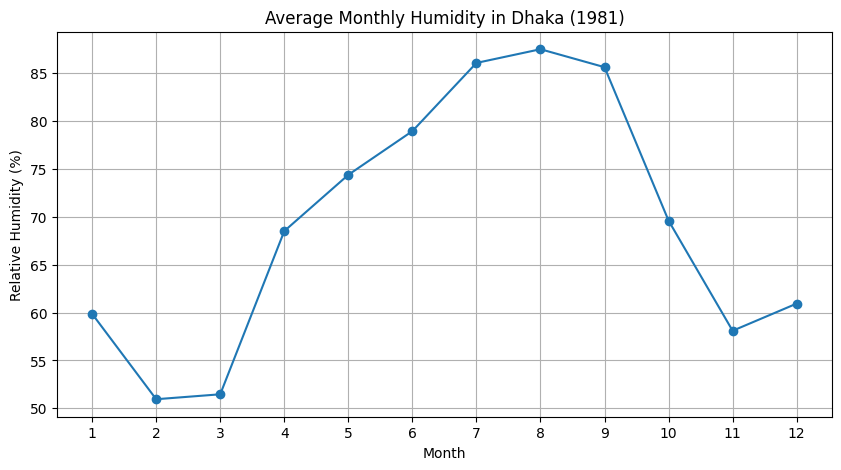

In [31]:
monthly_humidity = df.groupby("MONTH")["RH2M"].mean()

plt.figure(figsize=(10, 5))
monthly_humidity.plot(marker="o")

plt.title("Average Monthly Humidity in Dhaka (1981)")
plt.xlabel("Month")
plt.ylabel("Relative Humidity (%)")
plt.xticks(range(1, 13))
plt.grid(True)
plt.show()

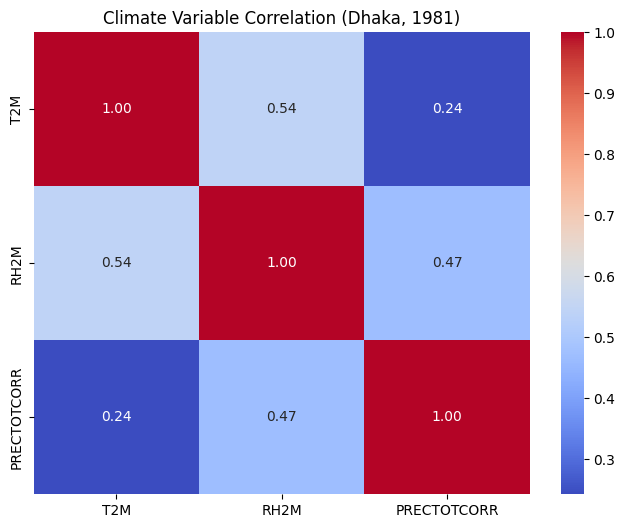

In [32]:
plt.figure(figsize=(8, 6))

sns.heatmap(
    df[["T2M", "RH2M", "PRECTOTCORR"]].corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Climate Variable Correlation (Dhaka, 1981)")
plt.show()

In [33]:
extreme_days = df[df["PRECTOTCORR"] >= 50]

print("Extreme Rainfall Days:", len(extreme_days))

extreme_days[["DATE", "T2M", "RH2M", "PRECTOTCORR"]]

Extreme Rainfall Days: 1


,DATE,T2M,RH2M,PRECTOTCORR
106,1981-04-17,26.41,85.35,84.61


In [34]:
extreme_temp = df[
    (df["T2M"] >= 35) | (df["T2M"] <= 10)
]

print("Extreme Temperature Days:", len(extreme_temp))

extreme_temp[["DATE", "T2M", "RH2M", "PRECTOTCORR"]]

Extreme Temperature Days: 0


,DATE,T2M,RH2M,PRECTOTCORR


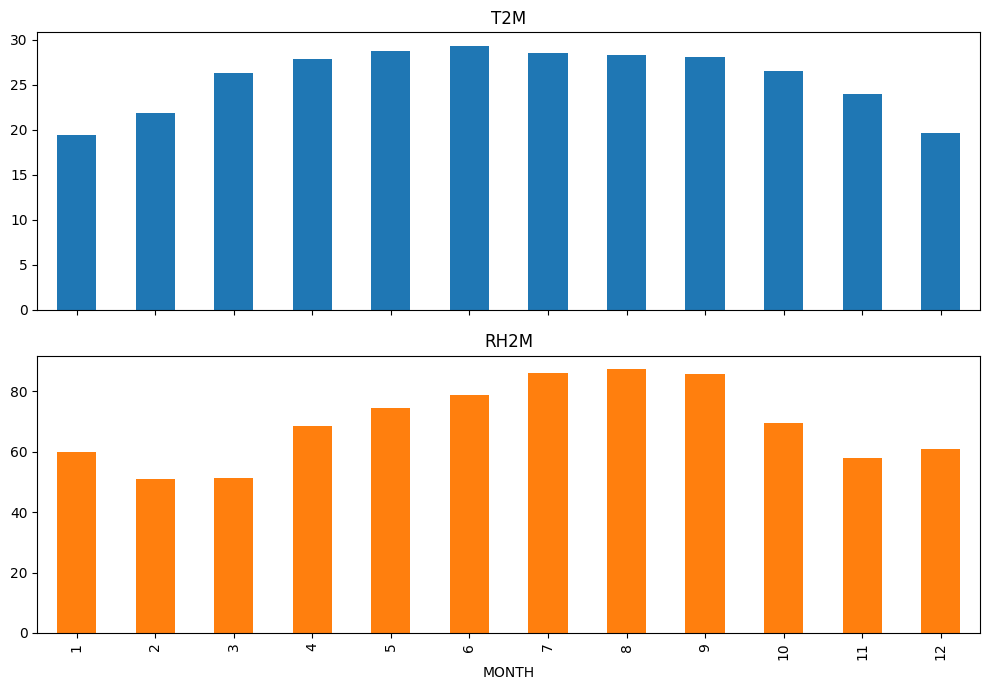

In [35]:
monthly_climate = df.groupby("MONTH")[["T2M", "RH2M"]].mean()

monthly_climate.plot(
    kind="bar",
    subplots=True,
    figsize=(10, 7),
    layout=(2, 1),
    legend=False
)

plt.tight_layout()
plt.show()

In [36]:
import os

os.makedirs("../data/processed", exist_ok=True)

df.to_csv("../data/processed/climate_data_cleaned.csv", index=False)

print("Cleaned dataset saved successfully!")

Cleaned dataset saved successfully!


In [37]:
yearly_summary = df.groupby("YEAR").agg({
    "T2M": ["mean", "min", "max"],
    "RH2M": "mean",
    "PRECTOTCORR": ["mean", "sum", "max"]
})

yearly_summary

T2M                     RH2M PRECTOTCORR                
           mean    min    max       mean        mean      sum    max
YEAR                                                                
1981  25.730137  16.31  30.99  69.442356    4.204082  1534.49  84.61

In [38]:
print("Dataset period:", df["DATE"].min(), "to", df["DATE"].max())
print("Total records:", len(df))

Dataset period: 1981-01-01 00:00:00 to 1981-12-31 00:00:00
Total records: 365


In [40]:
import os

print(os.listdir("../data"))

['POWER_Point_Daily_19810101_19811231_023d81N_090d41E_LST.csv', 'POWER_Point_Daily_19810101_20251231_023d81N_090d41E_LST.csv', 'processed']


In [41]:
df = pd.read_csv(
    "../data/POWER_Point_Daily_19810101_20251231_023d81N_090d41E_LST.csv",
    skiprows=11
)

print("Total records:", len(df))
df.head()

Total records: 16436


,YEAR,DOY,T2M,RH2M,PRECTOTCORR
0,1981,1,18.63,55.22,0.00
1,1981,2,19.06,51.12,0.00
2,1981,3,19.22,55.75,0.00
3,1981,4,19.11,53.51,0.00
4,1981,5,19.87,58.67,0.03


In [42]:
print("Total records:", len(df))
print("Start date:", df["YEAR"].min())
print("End date:", df["YEAR"].max())

Total records: 16436
Start date: 1981
End date: 2025


In [43]:
df["DATE"] = pd.to_datetime(
    df["YEAR"].astype(str) + df["DOY"].astype(str),
    format="%Y%j"
)

print(df[["DATE", "T2M", "RH2M", "PRECTOTCORR"]].head())
print("Date range:", df["DATE"].min(), "to", df["DATE"].max())

        DATE    T2M   RH2M  PRECTOTCORR
0 1981-01-01  18.63  55.22         0.00
1 1981-01-02  19.06  51.12         0.00
2 1981-01-03  19.22  55.75         0.00
3 1981-01-04  19.11  53.51         0.00
4 1981-01-05  19.87  58.67         0.03
Date range: 1981-01-01 00:00:00 to 2025-12-31 00:00:00


In [45]:
print("Missing values:")
print(df[["DATE", "T2M", "RH2M", "PRECTOTCORR"]].isnull().sum())

print("\nDuplicate dates:", df["DATE"].duplicated().sum())

print("\nDate range:", df["DATE"].min(), "to", df["DATE"].max())

Missing values:
DATE           0
T2M            0
RH2M           0
PRECTOTCORR    0
dtype: int64

Duplicate dates: 0

Date range: 1981-01-01 00:00:00 to 2025-12-31 00:00:00


In [46]:
yearly_summary = df.groupby("YEAR").agg(
    avg_temperature=("T2M", "mean"),
    avg_humidity=("RH2M", "mean"),
    total_rainfall=("PRECTOTCORR", "sum")
).reset_index()

yearly_summary.head()

,YEAR,avg_temperature,avg_humidity,total_rainfall
0,1981,25.730137,69.442356,1534.49
1,1982,25.855068,66.451041,1377.47
2,1983,26.351014,63.132795,1027.71
3,1984,25.775137,64.116257,1504.49
4,1985,26.416932,63.398411,1113.87


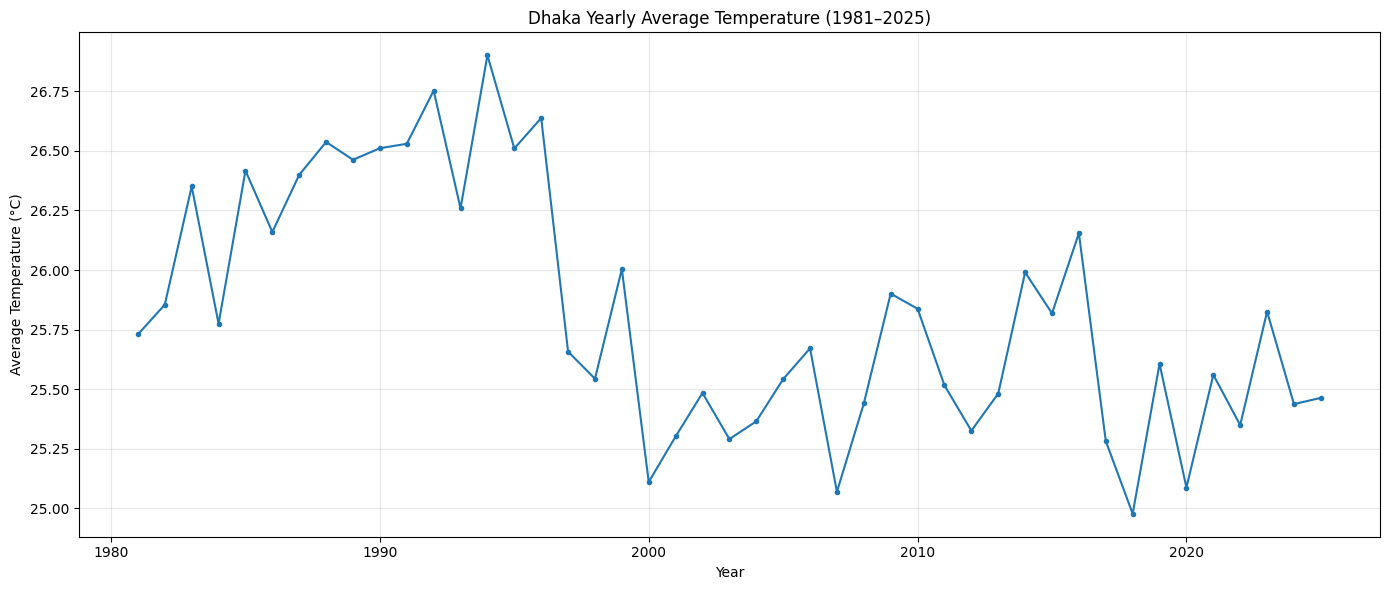

In [47]:
plt.figure(figsize=(14, 6))

plt.plot(
    yearly_summary["YEAR"],
    yearly_summary["avg_temperature"],
    marker="o",
    markersize=3
)

plt.title("Dhaka Yearly Average Temperature (1981–2025)")
plt.xlabel("Year")
plt.ylabel("Average Temperature (°C)")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

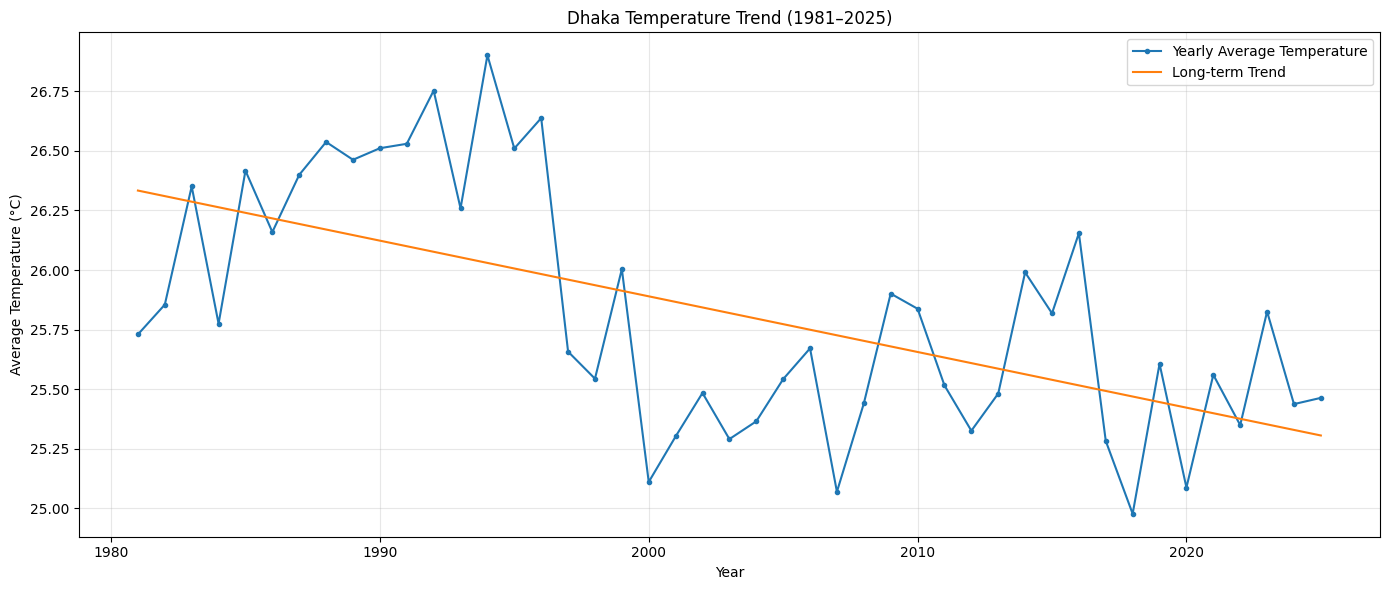

Estimated trend: -0.234 °C per decade


In [48]:
import numpy as np

x = yearly_summary["YEAR"]
y = yearly_summary["avg_temperature"]

slope, intercept = np.polyfit(x, y, 1)

plt.figure(figsize=(14, 6))
plt.plot(x, y, marker="o", markersize=3, label="Yearly Average Temperature")
plt.plot(x, slope * x + intercept, label="Long-term Trend")
plt.title("Dhaka Temperature Trend (1981–2025)")
plt.xlabel("Year")
plt.ylabel("Average Temperature (°C)")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

print(f"Estimated trend: {slope * 10:.3f} °C per decade")

In [49]:
yearly_summary["Decade"] = (yearly_summary["YEAR"] // 10) * 10

decade_summary = yearly_summary.groupby("Decade").agg(
    avg_temperature=("avg_temperature", "mean")
).reset_index()

print(decade_summary.round(3).to_string(index=False))

 Decade  avg_temperature
   1980           26.187
   1990           26.331
   2000           25.418
   2010           25.599
   2020           25.454


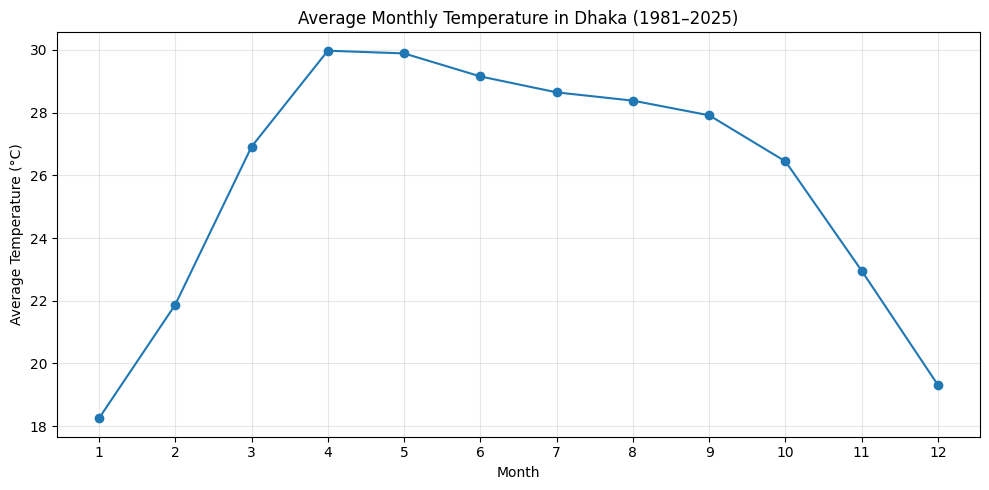

MONTH
1     18.25
2     21.87
3     26.91
4     29.98
5     29.89
6     29.16
7     28.65
8     28.38
9     27.91
10    26.44
11    22.95
12    19.31
Name: T2M, dtype: float64


In [50]:
df["MONTH"] = df["DATE"].dt.month

monthly_temperature = df.groupby("MONTH")["T2M"].mean()

plt.figure(figsize=(10, 5))
plt.plot(monthly_temperature.index, monthly_temperature.values, marker="o")

plt.title("Average Monthly Temperature in Dhaka (1981–2025)")
plt.xlabel("Month")
plt.ylabel("Average Temperature (°C)")
plt.xticks(range(1, 13))
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

print(monthly_temperature.round(2))

In [51]:
# Identify extreme rainfall days
extreme_rainfall = df[df["PRECTOTCORR"] >= 50].copy()

print("Extreme rainfall days:", len(extreme_rainfall))

print("\nFirst 10 extreme rainfall events:")
print(
    extreme_rainfall[
        ["DATE", "PRECTOTCORR", "T2M", "RH2M"]
    ].head(10).to_string(index=False)
)

print("\nMaximum daily rainfall:",
      df["PRECTOTCORR"].max(), "mm")

Extreme rainfall days: 134

First 10 extreme rainfall events:
      DATE  PRECTOTCORR   T2M  RH2M
1981-04-17        84.61 26.41 85.35
1982-05-05       100.71 27.85 81.41
1982-06-20        83.46 28.22 90.45
1982-08-03        50.72 27.43 90.48
1987-04-26        55.27 27.19 79.42
1988-06-26        66.42 28.15 90.74
1988-08-29        53.15 28.21 84.45
1991-05-05        52.40 28.22 81.48
1993-07-21        50.68 27.89 91.99
1997-07-11        64.75 27.88 92.85

Maximum daily rainfall: 167.28 mm


Top 10 years with most extreme rainfall days:
 YEAR  extreme_rainfall_days
 2017                     24
 2019                     12
 2024                     11
 2007                     10
 2023                      6
 2004                      6
 2006                      5
 2016                      5
 2025                      4
 2000                      4


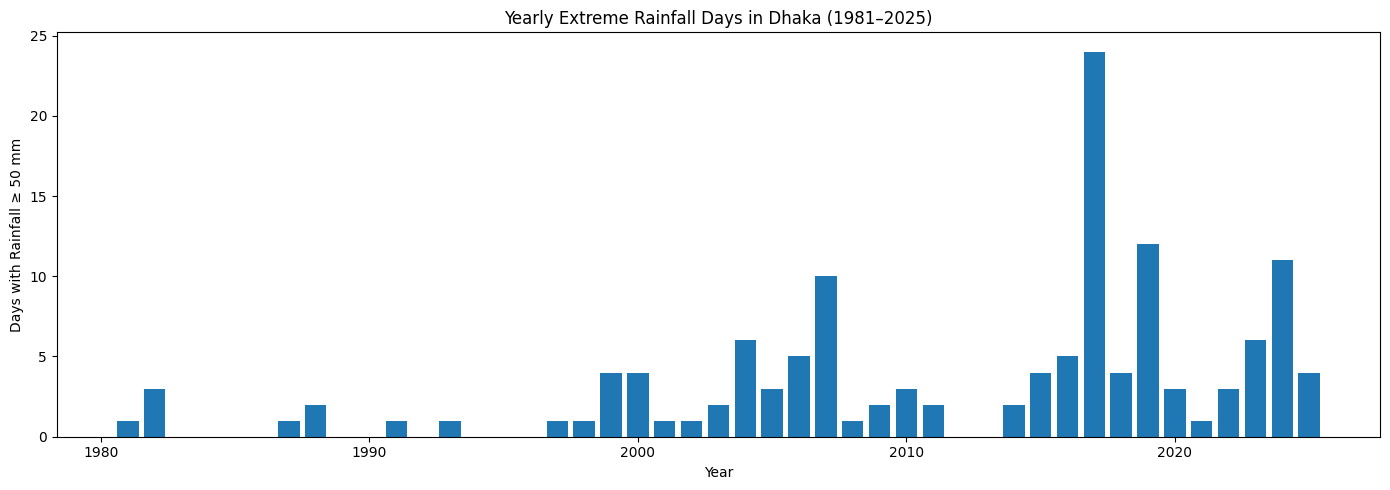

In [52]:
extreme_yearly = (
    extreme_rainfall.groupby(extreme_rainfall["DATE"].dt.year)
    .size()
    .reset_index(name="extreme_rainfall_days")
    .rename(columns={"DATE": "YEAR"})
)

print("Top 10 years with most extreme rainfall days:")
print(
    extreme_yearly
    .sort_values("extreme_rainfall_days", ascending=False)
    .head(10)
    .to_string(index=False)
)

plt.figure(figsize=(14, 5))
plt.bar(
    extreme_yearly["YEAR"],
    extreme_yearly["extreme_rainfall_days"]
)

plt.title("Yearly Extreme Rainfall Days in Dhaka (1981–2025)")
plt.xlabel("Year")
plt.ylabel("Days with Rainfall ≥ 50 mm")
plt.tight_layout()
plt.show()

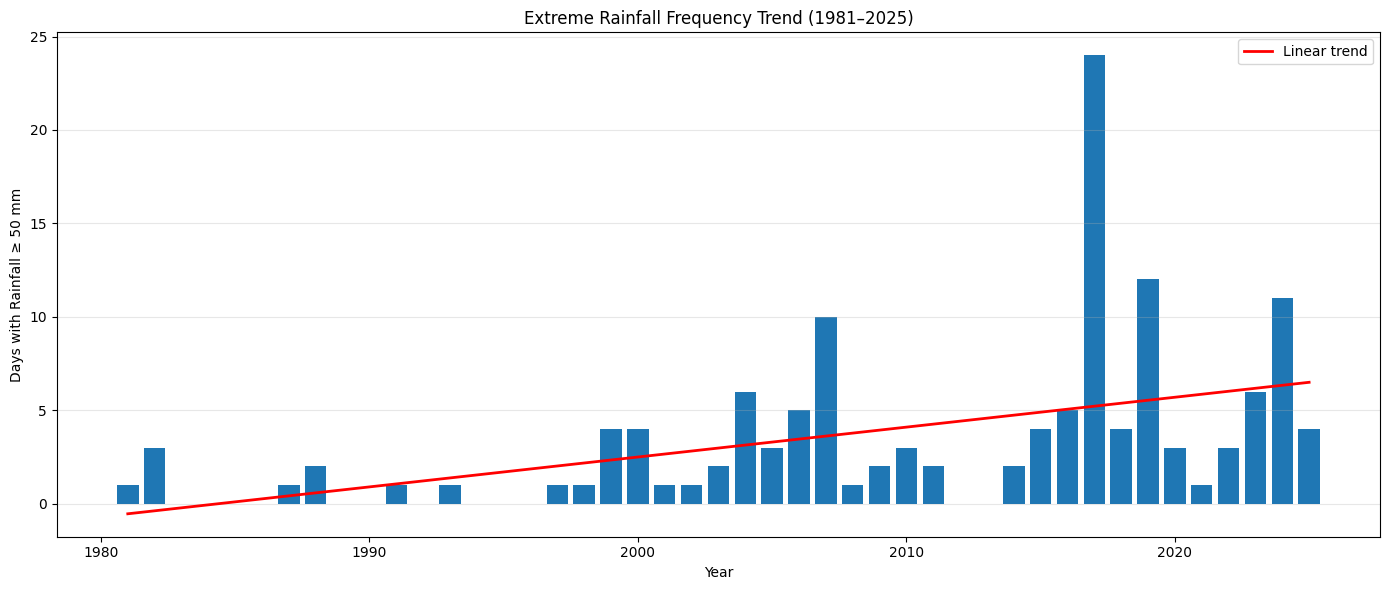

Trend: 0.160 extreme-rainfall days per year
Trend per decade: 1.60 days


In [53]:
# Count extreme rainfall days for every year, including years with zero events
yearly_extreme = (
    extreme_rainfall.groupby(extreme_rainfall["DATE"].dt.year)
    .size()
    .reindex(range(1981, 2026), fill_value=0)
)

slope, intercept = np.polyfit(
    yearly_extreme.index,
    yearly_extreme.values,
    1
)

plt.figure(figsize=(14, 6))

plt.bar(yearly_extreme.index, yearly_extreme.values)
plt.plot(
    yearly_extreme.index,
    slope * yearly_extreme.index + intercept,
    color="red",
    linewidth=2,
    label="Linear trend"
)

plt.title("Extreme Rainfall Frequency Trend (1981–2025)")
plt.xlabel("Year")
plt.ylabel("Days with Rainfall ≥ 50 mm")
plt.legend()
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

print(f"Trend: {slope:.3f} extreme-rainfall days per year")
print(f"Trend per decade: {slope * 10:.2f} days")

In [54]:
%pip install pymannkendall

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.3 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [55]:
import pymannkendall as mk

result = mk.original_test(yearly_extreme.values)

print("Trend:", result.trend)
print("P-value:", result.p)
print("Tau:", result.Tau)
print("Sen's slope:", result.slope)

Trend: increasing
P-value: 1.5117686573029587e-05
Tau: 0.4393939393939394
Sen's slope: 0.09878048780487805


In [56]:
df.to_csv(
    "../data/processed/climate_data_cleaned.csv",
    index=False
)

print("Cleaned dataset saved successfully!")
print("Total rows:", len(df))
print("Total columns:", len(df.columns))

Cleaned dataset saved successfully!
Total rows: 16436
Total columns: 7


In [57]:
temperature_test = mk.original_test(
    yearly_summary["avg_temperature"].values
)

print("Temperature trend:", temperature_test.trend)
print("P-value:", temperature_test.p)
print("Kendall's Tau:", temperature_test.Tau)
print("Sen's slope (°C/year):", temperature_test.slope)
print("Sen's slope (°C/decade):", temperature_test.slope * 10)

Temperature trend: decreasing
P-value: 0.00044499440544454316
Kendall's Tau: -0.36363636363636365
Sen's slope (°C/year): -0.020963854387995355
Sen's slope (°C/decade): -0.20963854387995356


In [58]:
print("Coldest 10 years:")
print(
    yearly_summary.nsmallest(10, "avg_temperature")[
        ["YEAR", "avg_temperature"]
    ].to_string(index=False)
)

print("\nWarmest 10 years:")
print(
    yearly_summary.nlargest(10, "avg_temperature")[
        ["YEAR", "avg_temperature"]
    ].to_string(index=False)
)

Coldest 10 years:
 YEAR  avg_temperature
 2018        24.977699
 2007        25.070110
 2020        25.087814
 2000        25.111175
 2017        25.283178
 2003        25.291041
 2001        25.302000
 2012        25.326066
 2022        25.349699
 2004        25.365601

Warmest 10 years:
 YEAR  avg_temperature
 1994        26.901096
 1992        26.752787
 1996        26.637541
 1988        26.537377
 1991        26.529699
 1990        26.511178
 1995        26.510055
 1989        26.462685
 1985        26.416932
 1987        26.399534


In [59]:
yearly_completeness = df.groupby("YEAR").agg(
    record_count=("DATE", "count"),
    unique_dates=("DATE", "nunique"),
    first_date=("DATE", "min"),
    last_date=("DATE", "max")
).reset_index()

yearly_completeness["expected_days"] = [
    366 if pd.Timestamp(year=int(y), month=12, day=31).is_leap_year else 365
    for y in yearly_completeness["YEAR"]
]

yearly_completeness["missing_days"] = (
    yearly_completeness["expected_days"]
    - yearly_completeness["unique_dates"]
)

print("Years with missing dates:")
print(
    yearly_completeness[
        yearly_completeness["missing_days"] != 0
    ].to_string(index=False)
)

print("\nMinimum records in any year:", yearly_completeness["record_count"].min())
print("Maximum records in any year:", yearly_completeness["record_count"].max())

Years with missing dates:
Empty DataFrame
Columns: [YEAR, record_count, unique_dates, first_date, last_date, expected_days, missing_days]
Index: []

Minimum records in any year: 365
Maximum records in any year: 366


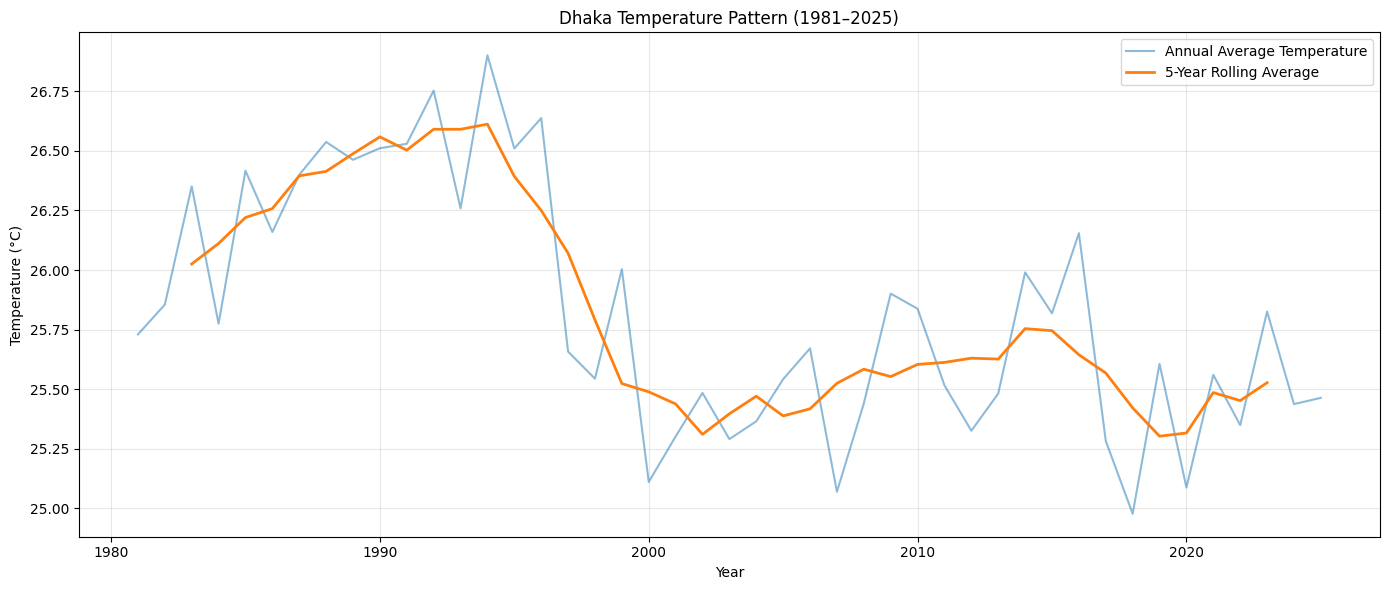

In [60]:
yearly_summary = yearly_summary.sort_values("YEAR").copy()

yearly_summary["temp_5yr_avg"] = (
    yearly_summary["avg_temperature"]
    .rolling(window=5, center=True)
    .mean()
)

plt.figure(figsize=(14, 6))

plt.plot(
    yearly_summary["YEAR"],
    yearly_summary["avg_temperature"],
    alpha=0.5,
    label="Annual Average Temperature"
)

plt.plot(
    yearly_summary["YEAR"],
    yearly_summary["temp_5yr_avg"],
    linewidth=2,
    label="5-Year Rolling Average"
)

plt.title("Dhaka Temperature Pattern (1981–2025)")
plt.xlabel("Year")
plt.ylabel("Temperature (°C)")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [61]:
early_period = yearly_summary[
    yearly_summary["YEAR"].between(1981, 2000)
]["avg_temperature"]

later_period = yearly_summary[
    yearly_summary["YEAR"].between(2001, 2025)
]["avg_temperature"]

print("1981–2000 average:", round(early_period.mean(), 3), "°C")
print("2001–2025 average:", round(later_period.mean(), 3), "°C")
print(
    "Difference (later - earlier):",
    round(later_period.mean() - early_period.mean(), 3),
    "°C"
)

1981–2000 average: 26.205 °C
2001–2025 average: 25.512 °C
Difference (later - earlier): -0.694 °C


In [62]:
df["PERIOD"] = np.where(
    df["YEAR"] <= 2000,
    "1981–2000",
    "2001–2025"
)

monthly_comparison = df.pivot_table(
    index=df["DATE"].dt.month,
    columns="PERIOD",
    values="T2M",
    aggfunc="mean"
)

monthly_comparison["Difference"] = (
    monthly_comparison["2001–2025"]
    - monthly_comparison["1981–2000"]
)

print(monthly_comparison.round(2))

PERIOD  1981–2000  2001–2025  Difference
DATE                                    
1           19.03      17.62       -1.41
2           22.32      21.52       -0.80
3           27.16      26.71       -0.45
4           30.35      29.68       -0.67
5           30.28      29.58       -0.69
6           29.67      28.74       -0.93
7           28.89      28.45       -0.44
8           28.55      28.25       -0.30
9           27.98      27.87       -0.11
10          26.68      26.25       -0.43
11          23.53      22.49       -1.04
12          19.90      18.83       -1.06


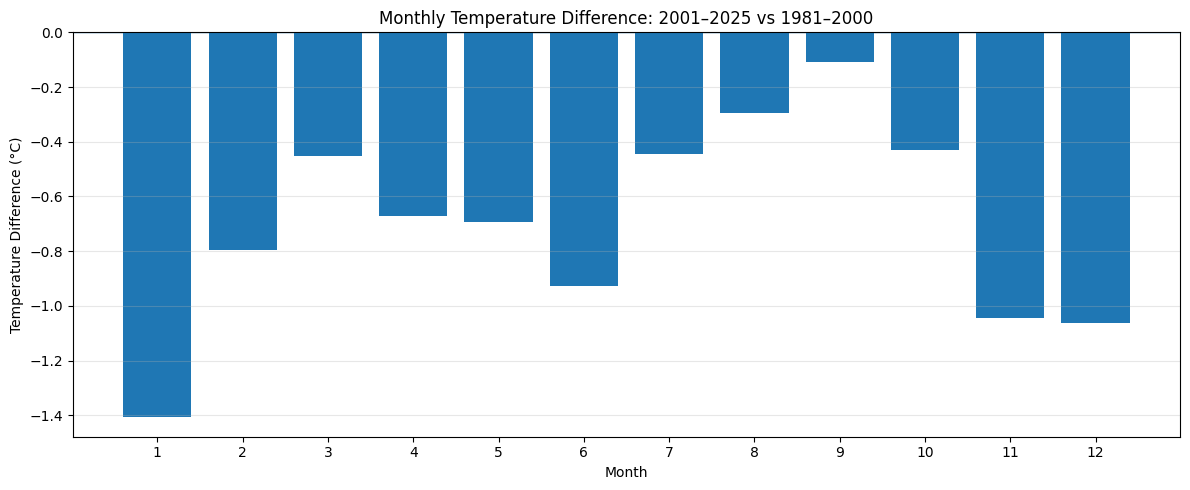

In [63]:
plt.figure(figsize=(12, 5))

plt.bar(
    monthly_comparison.index,
    monthly_comparison["Difference"]
)

plt.axhline(0, linewidth=1)
plt.title("Monthly Temperature Difference: 2001–2025 vs 1981–2000")
plt.xlabel("Month")
plt.ylabel("Temperature Difference (°C)")
plt.xticks(range(1, 13))
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

In [64]:
print("Temperature statistics:")
print(df["T2M"].describe().round(2))

print("\nLowest 10 temperature records:")
print(
    df.nsmallest(10, "T2M")[["DATE", "T2M"]]
    .to_string(index=False)
)

print("\nHighest 10 temperature records:")
print(
    df.nlargest(10, "T2M")[["DATE", "T2M"]]
    .to_string(index=False)
)

Temperature statistics:
count    16436.00
mean        25.82
std          4.32
min         10.71
25%         22.57
50%         27.53
75%         28.84
max         35.52
Name: T2M, dtype: float64

Lowest 10 temperature records:
      DATE   T2M
2013-01-09 10.71
2013-01-10 11.91
2013-01-08 12.16
2018-01-08 12.49
2018-01-07 12.56
2018-01-09 12.84
2018-01-11 12.84
2018-01-10 12.98
2013-01-11 13.26
2017-01-14 13.52

Highest 10 temperature records:
      DATE   T2M
1999-04-27 35.52
1999-04-28 35.47
1999-04-26 35.25
1999-04-29 34.81
1995-05-04 34.70
1995-05-03 34.67
1999-04-25 34.67
1995-05-02 34.66
1986-06-05 34.65
2014-04-25 34.51


In [65]:
decade_temperature = (
    df.groupby((df["YEAR"] // 10) * 10)["T2M"]
    .agg(["mean", "min", "max"])
    .round(2)
)

print(decade_temperature)

       mean    min    max
YEAR                     
1980  26.19  14.01  34.65
1990  26.33  13.54  35.52
2000  25.42  13.96  33.14
2010  25.60  10.71  34.51
2020  25.45  13.90  33.55


In [66]:
decade_climate = df.groupby((df["YEAR"] // 10) * 10).agg(
    avg_temperature=("T2M", "mean"),
    avg_humidity=("RH2M", "mean"),
    avg_daily_rainfall=("PRECTOTCORR", "mean"),
    total_rainfall=("PRECTOTCORR", "sum")
).round(2)

print(decade_climate)

      avg_temperature  avg_humidity  avg_daily_rainfall  total_rainfall
YEAR                                                                   
1980            26.19         64.77                3.47        11404.92
1990            26.33         64.91                3.40        12406.53
2000            25.42         74.30                5.32        19432.54
2010            25.60         74.87                6.38        23303.95
2020            25.45         77.40                7.17        15705.71


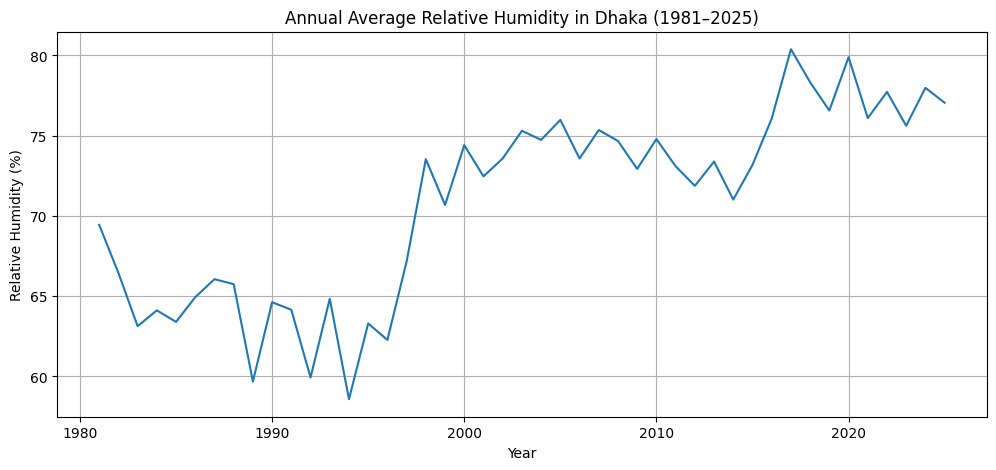

In [67]:
yearly_humidity = df.groupby("YEAR")["RH2M"].mean()

plt.figure(figsize=(12, 5))
plt.plot(yearly_humidity.index, yearly_humidity.values)
plt.title("Annual Average Relative Humidity in Dhaka (1981–2025)")
plt.xlabel("Year")
plt.ylabel("Relative Humidity (%)")
plt.grid(True)
plt.show()

In [68]:
humidity_trend = mk.original_test(yearly_humidity.values)

print("Trend:", humidity_trend.trend)
print("P-value:", humidity_trend.p)
print("Kendall Tau:", humidity_trend.Tau)
print("Sen's slope per year:", humidity_trend.slope)
print("Sen's slope per decade:", humidity_trend.slope * 10)

Trend: increasing
P-value: 6.595378465590329e-09
Kendall Tau: 0.6
Sen's slope per year: 0.3532921722113511
Sen's slope per decade: 3.532921722113511


In [69]:
yearly_rainfall = df.groupby("YEAR")["PRECTOTCORR"].sum()

rainfall_trend = mk.original_test(yearly_rainfall.values)

print("Trend:", rainfall_trend.trend)
print("P-value:", rainfall_trend.p)
print("Kendall Tau:", rainfall_trend.Tau)
print("Sen's slope per year:", rainfall_trend.slope)
print("Sen's slope per decade:", rainfall_trend.slope * 10)

Trend: increasing
P-value: 1.657597348270201e-08
Kendall Tau: 0.5838383838383838
Sen's slope per year: 38.00750000000001
Sen's slope per decade: 380.07500000000005


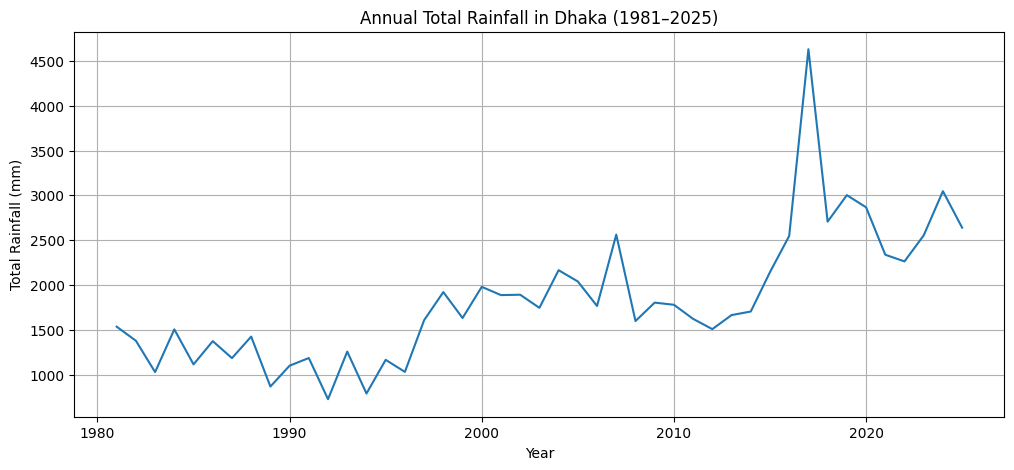

In [70]:
plt.figure(figsize=(12, 5))
plt.plot(yearly_rainfall.index, yearly_rainfall.values)
plt.title("Annual Total Rainfall in Dhaka (1981–2025)")
plt.xlabel("Year")
plt.ylabel("Total Rainfall (mm)")
plt.grid(True)
plt.show()

In [73]:
print("Most rainfall in 10 years:")
print(
    yearly_rainfall
    .sort_values(ascending=False)
    .head(10)
    .round(2)
)

Most rainfall in 10 years:
YEAR
2017    4630.54
2024    3046.40
2019    3002.23
2020    2866.91
2018    2706.29
2025    2639.40
2007    2561.87
2023    2552.90
2016    2546.88
2021    2337.26
Name: PRECTOTCORR, dtype: float64


In [74]:
rainfall_without_2017 = yearly_rainfall.drop(index=2017)

trend_without_2017 = mk.original_test(
    rainfall_without_2017.values
)

print("Trend:", trend_without_2017.trend)
print("P-value:", trend_without_2017.p)
print("Sen's slope per decade:", trend_without_2017.slope * 10)

Trend: increasing
P-value: 2.8124230055937005e-08
Sen's slope per decade: 371.5024122807017


In [75]:
trend_summary = pd.DataFrame({
    "Variable": ["Temperature", "Humidity", "Rainfall"],
    "Trend": [
        mk.original_test(yearly_summary["avg_temperature"].values).trend,
        humidity_trend.trend,
        rainfall_trend.trend
    ],
    "P-value": [
        mk.original_test(yearly_summary["avg_temperature"].values).p,
        humidity_trend.p,
        rainfall_trend.p
    ],
    "Sen slope per decade": [
        mk.original_test(yearly_summary["avg_temperature"].values).slope * 10,
        humidity_trend.slope * 10,
        rainfall_trend.slope * 10
    ]
})

print(trend_summary.round(4))

      Variable       Trend  P-value  Sen slope per decade
0  Temperature  decreasing   0.0004               -0.2096
1     Humidity  increasing   0.0000                3.5329
2     Rainfall  increasing   0.0000              380.0750


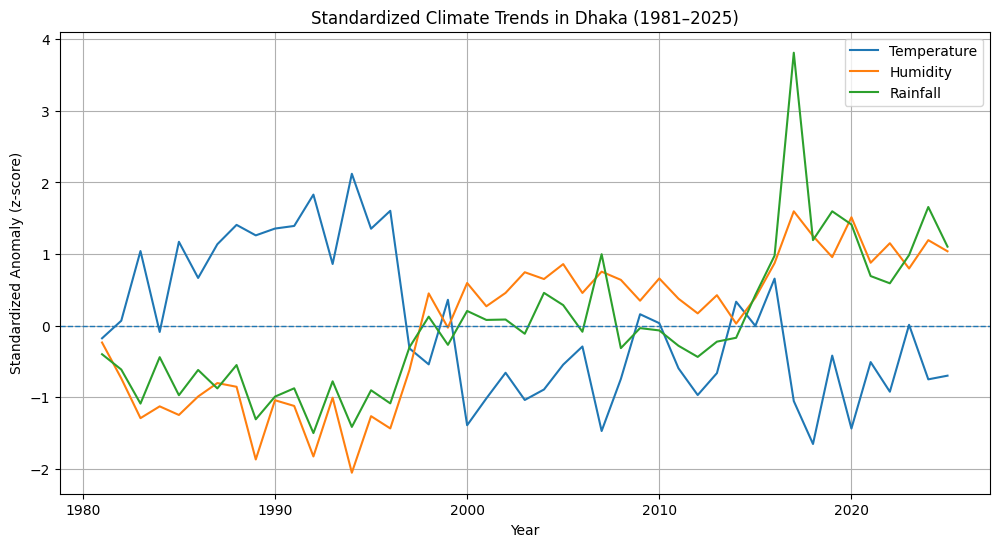

In [76]:
annual_climate = df.groupby("YEAR").agg(
    Temperature=("T2M", "mean"),
    Humidity=("RH2M", "mean"),
    Rainfall=("PRECTOTCORR", "sum")
)

standardized = (
    annual_climate - annual_climate.mean()
) / annual_climate.std()

plt.figure(figsize=(12, 6))

for column in standardized.columns:
    plt.plot(
        standardized.index,
        standardized[column],
        label=column
    )

plt.axhline(0, linestyle="--", linewidth=1)
plt.title("Standardized Climate Trends in Dhaka (1981–2025)")
plt.xlabel("Year")
plt.ylabel("Standardized Anomaly (z-score)")
plt.legend()
plt.grid(True)
plt.show()

In [77]:
print("Dataset period:", df["DATE"].min().date(), "to", df["DATE"].max().date())
print("Total daily records:", len(df))
print("Missing values:\n", df[["T2M", "RH2M", "PRECTOTCORR"]].isnull().sum())

Dataset period: 1981-01-01 to 2025-12-31
Total daily records: 16436
Missing values:
 T2M            0
RH2M           0
PRECTOTCORR    0
dtype: int64


In [78]:
trend_summary.to_csv(
    "../data/processed/climate_trend_summary.csv",
    index=False
)

print("Climate trend summary saved successfully!")
print(trend_summary)

Climate trend summary saved successfully!
      Variable       Trend       P-value  Sen slope per decade
0  Temperature  decreasing  4.449944e-04             -0.209639
1     Humidity  increasing  6.595378e-09              3.532922
2     Rainfall  increasing  1.657597e-08            380.075000


In [79]:
print("Temperature:", df["T2M"].describe())
print("\nHumidity:", df["RH2M"].describe())
print("\nRainfall:", df["PRECTOTCORR"].describe())

Temperature: count    16436.000000
mean        25.819862
std          4.316506
min         10.710000
25%         22.570000
50%         27.530000
75%         28.840000
max         35.520000
Name: T2M, dtype: float64

Humidity: count    16436.000000
mean        70.847198
std         17.586738
min         12.550000
25%         58.280000
50%         75.150000
75%         86.040000
max         95.770000
Name: RH2M, dtype: float64

Rainfall: count    16436.000000
mean         5.004481
std          9.949681
min          0.000000
25%          0.000000
50%          0.700000
75%          5.900000
max        167.280000
Name: PRECTOTCORR, dtype: float64


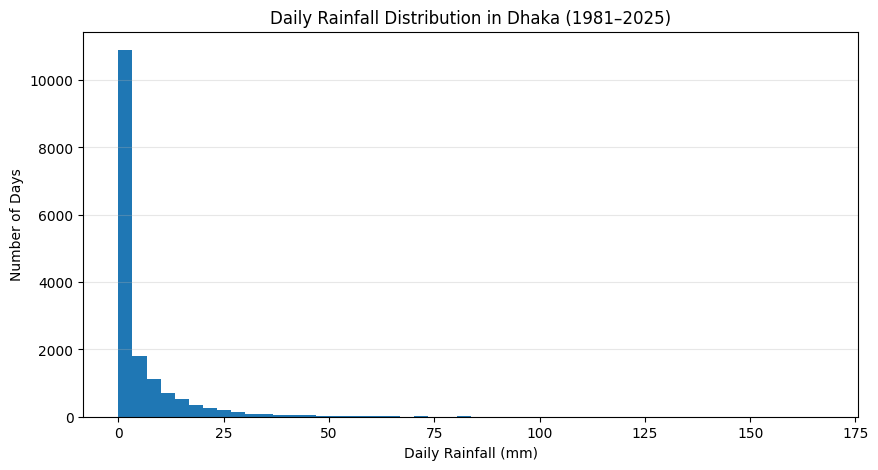

In [80]:
plt.figure(figsize=(10, 5))

plt.hist(df["PRECTOTCORR"], bins=50)

plt.title("Daily Rainfall Distribution in Dhaka (1981–2025)")
plt.xlabel("Daily Rainfall (mm)")
plt.ylabel("Number of Days")
plt.grid(axis="y", alpha=0.3)

plt.show()

In [81]:
dry_days = (df["PRECTOTCORR"] == 0).sum()
total_days = len(df)
dry_percentage = (dry_days / total_days) * 100

print("Days with zero rainfall:", dry_days)
print("Total days:", total_days)
print(f"Percentage of zero-rainfall days: {dry_percentage:.2f}%")

Days with zero rainfall: 5831
Total days: 16436
Percentage of zero-rainfall days: 35.48%


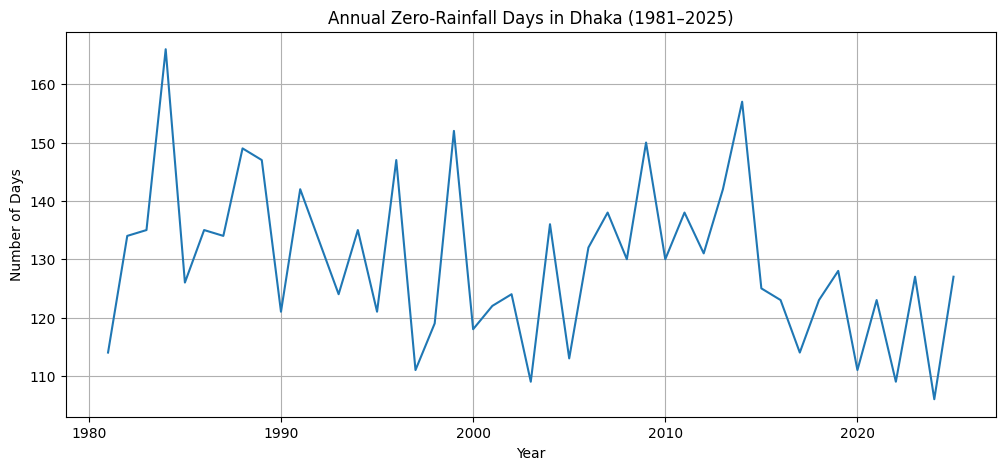

In [82]:
yearly_dry_days = (
    df[df["PRECTOTCORR"] == 0]
    .groupby("YEAR")
    .size()
)

yearly_dry_days = yearly_dry_days.reindex(
    range(1981, 2026), fill_value=0
)

plt.figure(figsize=(12, 5))
plt.plot(yearly_dry_days.index, yearly_dry_days.values)
plt.title("Annual Zero-Rainfall Days in Dhaka (1981–2025)")
plt.xlabel("Year")
plt.ylabel("Number of Days")
plt.grid(True)
plt.show()

In [83]:
dry_days_trend = mk.original_test(yearly_dry_days.values)

print("Trend:", dry_days_trend.trend)
print("P-value:", dry_days_trend.p)
print("Kendall Tau:", dry_days_trend.Tau)
print("Sen's slope per decade:", dry_days_trend.slope * 10)

Trend: decreasing
P-value: 0.04795531005302034
Kendall Tau: -0.20505050505050504
Sen's slope per decade: -2.9705882352941178


In [84]:
rainfall_days = pd.Series({
    "Zero rainfall": (df["PRECTOTCORR"] == 0).sum(),
    "Light rainfall (0–10 mm)": (
        (df["PRECTOTCORR"] > 0) &
        (df["PRECTOTCORR"] < 10)
    ).sum(),
    "Moderate rainfall (10–50 mm)": (
        (df["PRECTOTCORR"] >= 10) &
        (df["PRECTOTCORR"] < 50)
    ).sum(),
    "Heavy rainfall (>=50 mm)": (
        df["PRECTOTCORR"] >= 50
    ).sum()
})

print(rainfall_days)

Zero rainfall                   5831
Light rainfall (0–10 mm)        7985
Moderate rainfall (10–50 mm)    2486
Heavy rainfall (>=50 mm)         134
dtype: int64


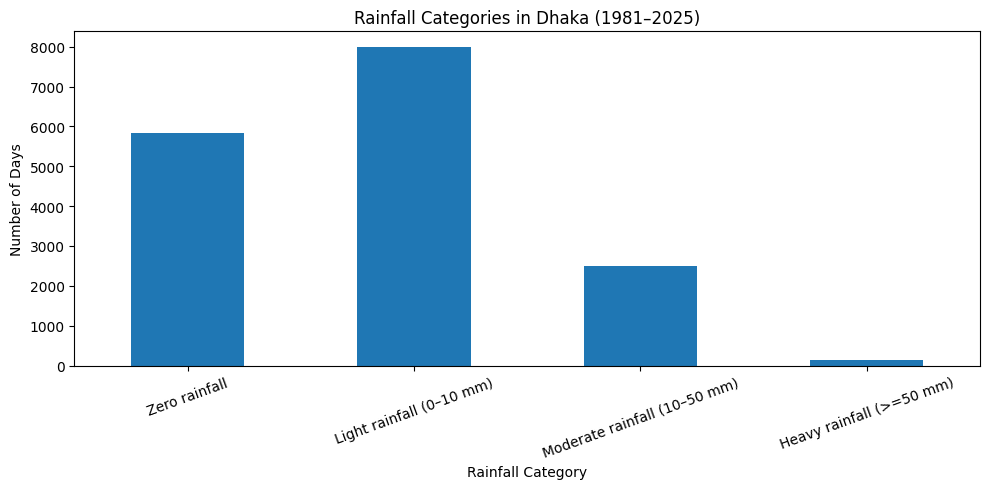

In [85]:
rainfall_days.plot(
    kind="bar",
    figsize=(10, 5),
    title="Rainfall Categories in Dhaka (1981–2025)",
    ylabel="Number of Days",
    xlabel="Rainfall Category",
    rot=20
)

plt.tight_layout()
plt.show()

In [86]:
yearly_heavy_rain = (
    df[df["PRECTOTCORR"] >= 50]
    .groupby("YEAR")
    .size()
    .reindex(range(1981, 2026), fill_value=0)
)

heavy_rain_trend = mk.original_test(yearly_heavy_rain.values)

print("Trend:", heavy_rain_trend.trend)
print("P-value:", heavy_rain_trend.p)
print("Kendall Tau:", heavy_rain_trend.Tau)
print("Sen's slope per decade:", heavy_rain_trend.slope * 10)

Trend: increasing
P-value: 1.5117686573029587e-05
Kendall Tau: 0.4393939393939394
Sen's slope per decade: 0.9878048780487805


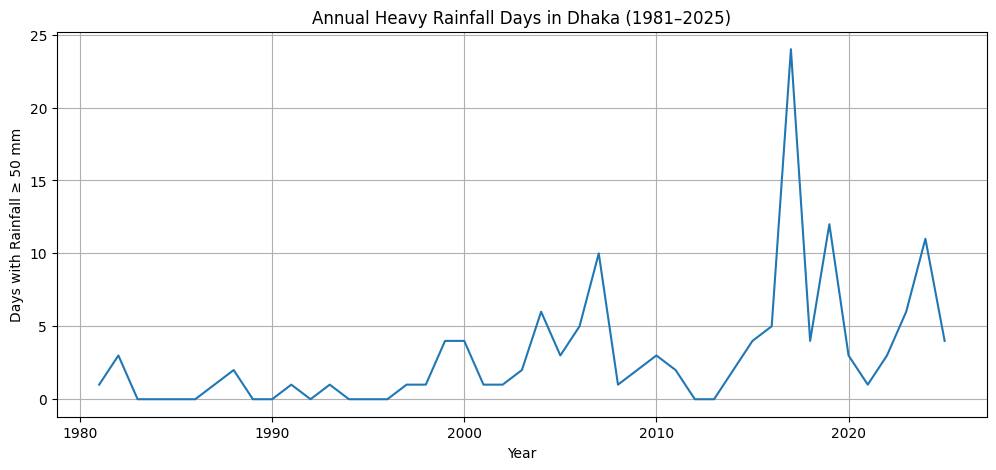

In [87]:
plt.figure(figsize=(12, 5))

plt.plot(
    yearly_heavy_rain.index,
    yearly_heavy_rain.values
)

plt.title("Annual Heavy Rainfall Days in Dhaka (1981–2025)")
plt.xlabel("Year")
plt.ylabel("Days with Rainfall ≥ 50 mm")
plt.grid(True)

plt.show()

In [88]:
heavy_rain_summary = pd.DataFrame({
    "YEAR": yearly_heavy_rain.index,
    "HEAVY_RAIN_DAYS": yearly_heavy_rain.values
})

heavy_rain_summary.to_csv(
    "../data/processed/yearly_heavy_rainfall.csv",
    index=False
)

print("Heavy rainfall summary saved successfully!")
print(heavy_rain_summary.head())

Heavy rainfall summary saved successfully!
   YEAR  HEAVY_RAIN_DAYS
0  1981                1
1  1982                3
2  1983                0
3  1984                0
4  1985                0


In [89]:
final_results = pd.DataFrame({
    "Climate Variable": [
        "Annual Temperature",
        "Annual Humidity",
        "Annual Rainfall",
        "Zero-Rainfall Days",
        "Heavy-Rainfall Days"
    ],
    "Trend": [
        mk.original_test(yearly_summary["avg_temperature"].values).trend,
        humidity_trend.trend,
        rainfall_trend.trend,
        dry_days_trend.trend,
        heavy_rain_trend.trend
    ],
    "P-value": [
        mk.original_test(yearly_summary["avg_temperature"].values).p,
        humidity_trend.p,
        rainfall_trend.p,
        dry_days_trend.p,
        heavy_rain_trend.p
    ]
})

print(final_results.round(6))

      Climate Variable       Trend   P-value
0   Annual Temperature  decreasing  0.000445
1      Annual Humidity  increasing  0.000000
2      Annual Rainfall  increasing  0.000000
3   Zero-Rainfall Days  decreasing  0.047955
4  Heavy-Rainfall Days  increasing  0.000015


In [90]:
final_results.to_csv(
    "../data/processed/final_climate_results.csv",
    index=False
)

print("Final climate results saved successfully!")

Final climate results saved successfully!
